# Notebook dedictaed to Study the Driven effect in the CID distribution (Angular unbalance of the scintillation light distribution). 
The idea is to check the relation between the direction between the reconstructed and truth position and the truth event direction

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn
import glob 

# Load the Data

In [2]:
fdir = '/home/joankl/data/solars/mc/2p2PPO/electrons/results_npz/resume/resume_npz/'
flist = sorted(glob.glob(fdir + 'e_*MeV_resumed.npz'))

observable_list = ['evtid', 'mcid', 'energy_mc', 'pos_mc', 'pos_recon', 'dir_mc']

data_dict = {obs_i: [] for obs_i in observable_list}

for file_i in flist:
    np_data = np.load(file_i)

    for obs_i in observable_list:
        data_dict[obs_i].append(np_data[obs_i])

for obs_i in observable_list:
    data_dict[obs_i] = np.concatenate(data_dict[obs_i], axis = 0)

# Select per Event Observables

In [3]:
mcid = data_dict['mcid']

# Look when the mcid breaks (difference betweeen consequtive elements != 0) to spot the per event entries
event_start_indices = np.concatenate(([0], np.where(np.diff(mcid) != 0)[0] + 1))

pos_mc = data_dict['pos_mc'][event_start_indices]
pos_recon = data_dict['pos_recon'][event_start_indices]
dir_mc = data_dict['dir_mc'][event_start_indices]

# Construct Observables of Interest

In [29]:
driven_vec = pos_recon - pos_mc # vector pointing from the truth position to the recons. position
driven_vec = driven_vec / np.linalg.norm(driven_vec, axis=1, keepdims=True)  # Normalize the vector

# Scalar Product: (Sensible to the angle between the event direction and driven vertex vector)
scalar_prod = np.vecdot(driven_vec, dir_mc, axis=1)  # cos(angle)

# Plots

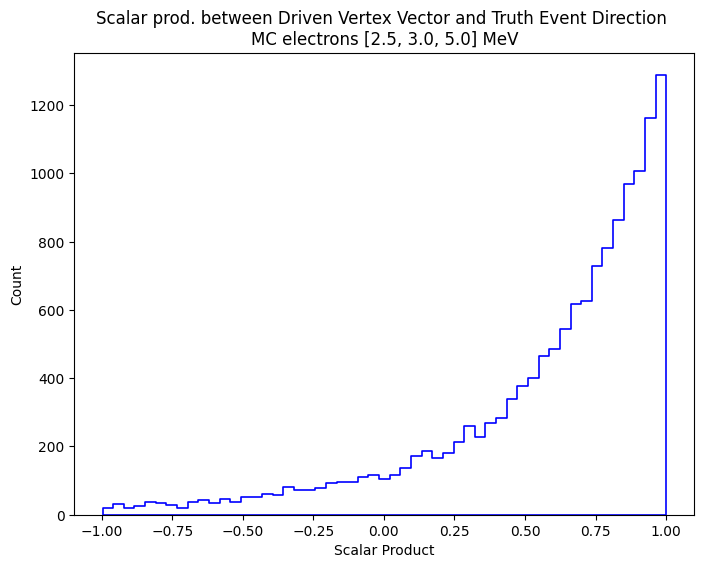

In [33]:
bins = 'auto'

plt.subplots(figsize = (8, 6))


sn.histplot(scalar_prod, bins=bins, element = 'step', alpha = 0, lw = 1.2, color = 'blue')

plt.xlabel(r'Scalar Product')
plt.title('Scalar prod. between Driven Vertex Vector and Truth Event Direction \n' + rf'MC electrons {np.unique(data_dict['energy_mc']).tolist()} MeV')


plt.show()